# Experiment 8: Named Entity Recognition using NLTK
**AIM:** To identify named entities in text using Natural Language Processing techniques.

**OBJECTIVE:** To tokenize and tag text, apply named entity recognition, and identify entities such as people, organizations, locations, and other supported categories.

In [1]:
import nltk
from nltk import word_tokenize, pos_tag, ne_chunk
from nltk.tree import Tree
from collections import Counter
import matplotlib.pyplot as plt

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('maxent_ne_chunker_tab', quiet=True)
nltk.download('words', quiet=True)

True

In [2]:
text = ("Sundar Pichai is the CEO of Google, which is headquartered in Mountain View, California. "
        "Narendra Modi met Joe Biden in New Delhi to discuss trade with the United Nations.")

# 1. Tokenize -> 2. POS tag -> 3. Named-entity chunking
tokens = word_tokenize(text)
tagged = pos_tag(tokens)
tree = ne_chunk(tagged)

In [3]:
# 4. Extract entities from the chunk tree
entities = []
for node in tree:
    if isinstance(node, Tree):
        name = " ".join(w for w, t in node.leaves())
        entities.append((name, node.label()))

print(f"{'Entity':<22}Label")
print("-" * 34)
for e, l in entities:
    print(f"{e:<22}{l}")

Entity                Label
----------------------------------
Sundar                PERSON
Pichai                PERSON
CEO of Google         ORGANIZATION
Mountain View         GPE
California            GPE
Narendra Modi         PERSON
Joe Biden             PERSON
New Delhi             GPE
United Nations        ORGANIZATION


In [4]:
# 5. Group entities by category
groups = {}
for e, l in entities:
    groups.setdefault(l, []).append(e)

print("Grouped Entities:")
for l, es in groups.items():
    print(f"  {l:<13}: {es}")

# 6. Binary NER (entity / not entity)
binary = ne_chunk(tagged, binary=True)
print("\nBinary NE chunks:", [" ".join(w for w, t in n.leaves()) for n in binary if isinstance(n, Tree)])

# 7. Chunk tree of a single sentence
print("\nChunk tree:")
print(ne_chunk(pos_tag(word_tokenize("Sundar Pichai is the CEO of Google."))))

Grouped Entities:
  PERSON       : ['Sundar', 'Pichai', 'Narendra Modi', 'Joe Biden']
  ORGANIZATION : ['CEO of Google', 'United Nations']
  GPE          : ['Mountain View', 'California', 'New Delhi']

Binary NE chunks: ['Sundar Pichai', 'Google', 'Mountain View', 'California', 'Narendra Modi', 'Joe Biden', 'New Delhi', 'United Nations']

Chunk tree:
(S
  (PERSON Sundar/NNP)
  (PERSON Pichai/NNP)
  is/VBZ
  the/DT
  (ORGANIZATION CEO/NN of/IN Google/NNP)
  ./.)


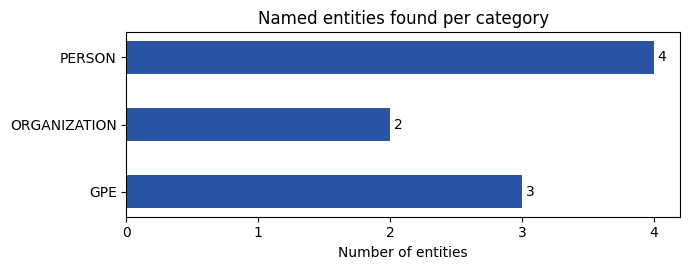

In [5]:
# ---------------- Visualization ----------------
BLUE = '#2B54A3'
c = Counter(l for _, l in entities)
plt.figure(figsize=(7, 2.8))
b = plt.barh(list(c.keys()), list(c.values()), color=BLUE, height=0.5)
plt.bar_label(b, padding=3)
plt.gca().invert_yaxis()
plt.xticks(range(0, max(c.values()) + 1))
plt.xlabel('Number of entities')
plt.title('Named entities found per category')
plt.tight_layout()
plt.show()